# Polymarket 5-Minute Up/Down — Double-Dip Arbitrage (trade tape)

**Strategy.** In each recurring 5-minute crypto Up/Down market, place a resting BUY
at `<= threshold` (e.g. $0.45) on **both** tokens. The legs fill **independently, at
different times** (intra-window overshoot):

- **Both legs fill** for combined cost `< $1.00` &rarr; one side settles $1 &rarr; **locked, risk-free arbitrage**.
- **Only one leg fills** &rarr; **unhedged**: settles $1 (win) or **$0 (the core risk)**.

**Data.** This notebook uses *only* the high-fidelity **executed trade tape**
(`data-api.polymarket.com/trades`) — ~2000–3000 real trades/window. The coarse
1-minute `/prices-history` mid path is excluded by design. Every executed trade
settles on Polygon, so the tape is the accurate, look-ahead-safe history.

**Fill model (look-ahead-safe).** A resting BUY at `T` fills when the price
**trades through** `T` (`fill_mode="trade_through"`, the standard limit rule);
`sell_through` (fill only on a SELL print `<= T`) is the conservative bound. We
execute at our limit `T`, exclude the post-close settlement tail, and run YES/NO as
independent streams — the true temporal double-dip. Resting **book depth** is not in
any historical feed (off-chain); the live CLOB collector gathers it going forward.

In [1]:
import sys, os, logging
sys.path.insert(0, os.path.abspath(".."))
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
logging.basicConfig(level=logging.WARNING)

from polymarket_arb import (TapeBacktester, TapeConfig, tape_threshold_sweep,
                            summary, ActiveExitBacktester, ActiveConfig)
from polymarket_arb.optimize import tape_param_grid
from polymarket_arb.trades import TradeHistoryClient
from polymarket_arb.engine import ARB_LOCKED
from polymarket_arb.active import EXIT_WIN, EXIT_LOSS
pd.set_option("display.width", 120); plt.rcParams["figure.figsize"] = (10, 4)

ASSET, COUNT = "btc", 300
thc = TradeHistoryClient(cache_dir="../.cache")
tape_windows = [w for w in thc.load_history(ASSET, count=COUNT) if w.resolved and w.n_trades > 0]
TAPE_OK = len(tape_windows) >= 5
tt = [w.n_trades for w in tape_windows]
print(f"{len(tape_windows)} {ASSET} windows | total trades {sum(tt):,} | "
      f"median {sorted(tt)[len(tt)//2]}/window | truncated(>4000) {sum(w.truncated for w in tape_windows)}")

300 btc windows | total trades 715,009 | median 2296/window | truncated(>4000) 9


## 1 — The executed trade tape & the double-dip in action

A single 5-minute window holds thousands of real trades. Below is one window that
**locks** (both legs trade `<= T` at different moments).

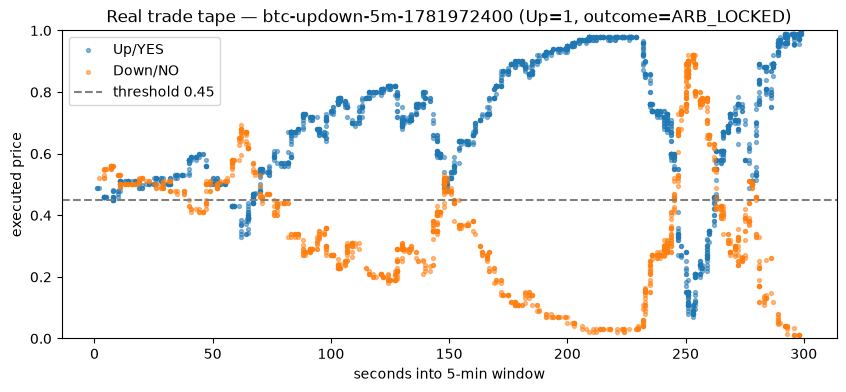

In [2]:
# A window that locks arb (both legs dip <= T at different times)
if TAPE_OK:
    bt = TapeBacktester(TapeConfig(threshold=0.45))
    res_t = bt.run(tape_windows)
    pick_i = next((i for i, r in enumerate(res_t) if r.outcome == ARB_LOCKED), 0)
    pick = tape_windows[pick_i]
    fig, ax = plt.subplots(figsize=(10, 4))
    for tr, c, lbl in [(pick.yes_trades, "tab:blue", "Up/YES"), (pick.no_trades, "tab:orange", "Down/NO")]:
        pts = [(t.ts - pick.open_ts, t.price) for t in tr]
        if pts:
            ax.scatter([p[0] for p in pts], [p[1] for p in pts], s=8, c=c, alpha=.5, label=lbl)
    ax.axhline(0.45, ls="--", c="grey", label="threshold 0.45")
    ax.set_xlabel("seconds into 5-min window"); ax.set_ylabel("executed price"); ax.set_ylim(0, 1)
    ax.set_title(f"Real trade tape — {pick.slug} (Up={pick.resolution_yes:.0f}, outcome={res_t[pick_i].outcome})")
    ax.legend(); plt.show()

In [3]:
# Per-window table + summary on the real tape (T=0.45)
if TAPE_OK:
    rows = [{"slug": r.slug[-18:], "res_yes": r.resolution_yes, "legs": r.n_legs,
             "cost": round(r.cost, 3), "payout": round(r.payout, 3),
             "pnl": round(r.pnl, 3), "outcome": r.outcome} for r in res_t[:12]]
    display(pd.DataFrame(rows))
    st = summary(res_t)
    keys = ["n_windows","total_pnl","avg_pnl_per_window","fill_rate","both_fill_rate",
            "arb_lock_rate","unhedged_loss_rate","unhedged_win_rate","win_rate",
            "max_drawdown","profit_factor"]
    display(pd.Series({k: round(st[k], 4) for k in keys}).to_frame("tape model @ T=0.45"))
    print("counts:", st["counts"])

,slug,res_yes,legs,cost,payout,pnl,outcome
0,down-5m-1781972400,1.0,2,0.90,1.0,0.10,ARB_LOCKED
1,down-5m-1781972100,1.0,1,0.45,0.0,-0.45,UNHEDGED_LOSS
2,down-5m-1781971800,0.0,2,0.90,1.0,0.10,ARB_LOCKED
3,down-5m-1781971500,1.0,2,0.90,1.0,0.10,ARB_LOCKED
4,down-5m-1781971200,0.0,2,0.90,1.0,0.10,ARB_LOCKED
5,down-5m-1781970900,1.0,2,0.90,1.0,0.10,ARB_LOCKED
6,down-5m-1781970600,0.0,1,0.45,0.0,-0.45,UNHEDGED_LOSS
7,down-5m-1781970300,1.0,2,0.90,1.0,0.10,ARB_LOCKED
8,down-5m-1781970000,0.0,1,0.45,0.0,-0.45,UNHEDGED_LOSS
9,down-5m-1781969700,0.0,1,0.45,0.0,-0.45,UNHEDGED_LOSS


,tape model @ T=0.45
n_windows,300.0000
total_pnl,-17.5750
avg_pnl_per_window,-0.0586
fill_rate,1.0000
both_fill_rate,0.7133
arb_lock_rate,0.7100
unhedged_loss_rate,0.2867
unhedged_win_rate,0.0000
win_rate,0.7100
max_drawdown,17.2250


counts: {'ARB_LOCKED': 213, 'HEDGED_NEGEDGE': 1, 'UNHEDGED_WIN': 0, 'UNHEDGED_LOSS': 86, 'NO_FILL': 0}


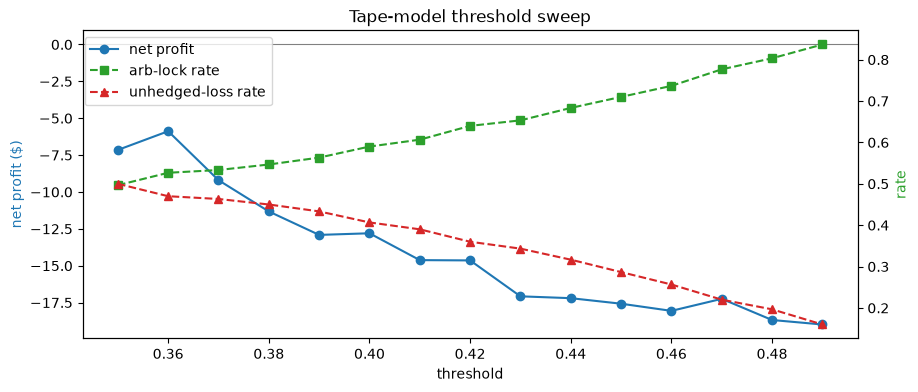

,threshold,net_profit,arb_lock_rate,unhedged_loss_rate,profit_factor
0,0.35,-7.150,0.497,0.500,0.864
1,0.36,-5.880,0.527,0.470,0.884
2,0.37,-9.200,0.533,0.463,0.821
3,0.38,-11.320,0.547,0.450,0.779
4,0.39,-12.910,0.563,0.433,0.745
5,0.40,-12.800,0.590,0.407,0.738
6,0.41,-14.620,0.607,0.390,0.695
7,0.42,-14.640,0.640,0.360,0.677
8,0.43,-17.075,0.653,0.343,0.616
9,0.44,-17.200,0.683,0.317,0.589


In [4]:
# Threshold sweep + fee surface
if TAPE_OK:
    tsw = tape_threshold_sweep(tape_windows, np.round(np.arange(0.35, 0.495, 0.01), 3))
    fig, ax1 = plt.subplots()
    ax1.plot(tsw.threshold, tsw.net_profit, "o-", color="tab:blue", label="net profit")
    ax1.axhline(0, c="grey", lw=.8); ax1.set_xlabel("threshold"); ax1.set_ylabel("net profit ($)", color="tab:blue")
    ax2 = ax1.twinx()
    ax2.plot(tsw.threshold, tsw.arb_lock_rate, "s--", color="tab:green", label="arb-lock rate")
    ax2.plot(tsw.threshold, tsw.unhedged_loss_rate, "^--", color="tab:red", label="unhedged-loss rate")
    ax2.set_ylabel("rate", color="tab:green")
    fig.legend(loc="upper left", bbox_to_anchor=(0.12, 0.88)); plt.title("Tape-model threshold sweep"); plt.show()
    display(tsw[["threshold","net_profit","arb_lock_rate","unhedged_loss_rate","profit_factor"]].round(3))

## 2 — Data-driven threshold selection

Analyse the tape first (when do trades happen, how deep does each side reverse),
then read the optimal threshold off the P&L curve.

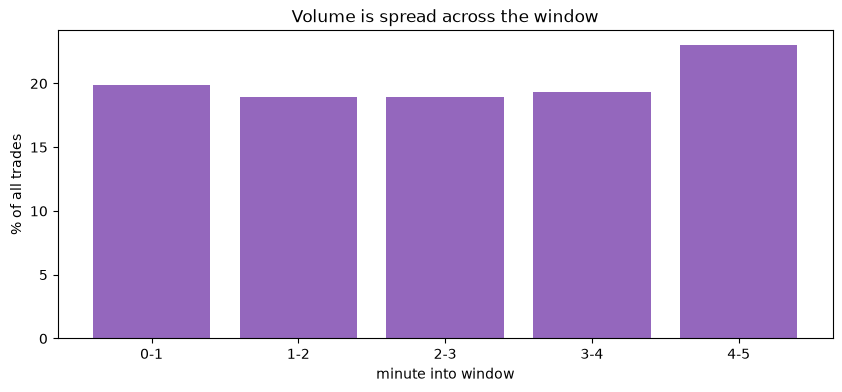

trades per minute (%): [19.8 18.9 18.9 19.3 23. ]


In [5]:
# When do trades occur within the window? (early reversals are real)
if TAPE_OK:
    buckets = np.zeros(5)
    for w in tape_windows:
        for t in w.yes_trades + w.no_trades:
            buckets[min(int((t.ts - w.open_ts) / 60), 4)] += 1
    plt.bar(range(5), buckets / buckets.sum() * 100, color="tab:purple")
    plt.xticks(range(5), ["0-1","1-2","2-3","3-4","4-5"]); plt.xlabel("minute into window")
    plt.ylabel("% of all trades"); plt.title("Volume is spread across the window"); plt.show()
    print("trades per minute (%):", np.round(buckets / buckets.sum() * 100, 1))

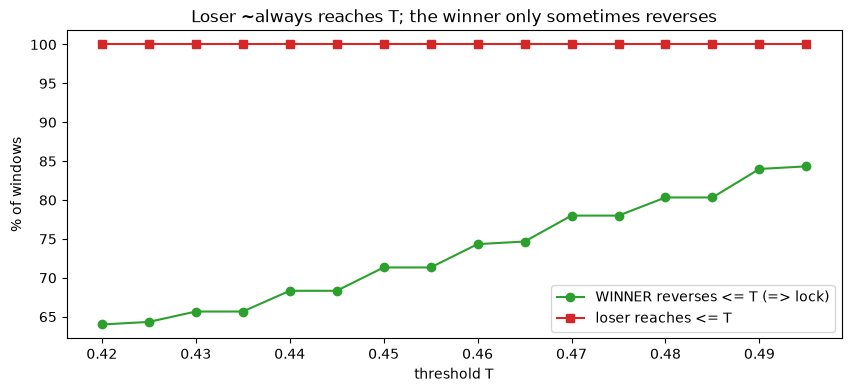

In [6]:
# Reversal depth: winner vs loser minimum price reached
if TAPE_OK:
    def wl_mins(w):
        ymin = min((t.price for t in w.yes_trades), default=1.0)
        nmin = min((t.price for t in w.no_trades), default=1.0)
        win = ymin if w.resolution_yes == 1.0 else nmin
        los = nmin if w.resolution_yes == 1.0 else ymin
        return win, los
    wl = [wl_mins(w) for w in tape_windows]
    Ts = np.round(np.arange(0.42, 0.498, 0.005), 3)
    winr = [100 * np.mean([wm <= T for wm, _ in wl]) for T in Ts]
    losr = [100 * np.mean([lm <= T for _, lm in wl]) for T in Ts]
    plt.plot(Ts, winr, "o-", color="tab:green", label="WINNER reverses <= T (=> lock)")
    plt.plot(Ts, losr, "s-", color="tab:red", label="loser reaches <= T")
    plt.xlabel("threshold T"); plt.ylabel("% of windows"); plt.legend()
    plt.title("Loser ~always reaches T; the winner only sometimes reverses"); plt.show()

trade_through: optimal T=0.440  net=$ -17.20  both-fill=68.3%  unhedged-loss=31.7%


sell_through : optimal T=0.440  net=$ -25.54  both-fill=63.7%  unhedged-loss=36.3%


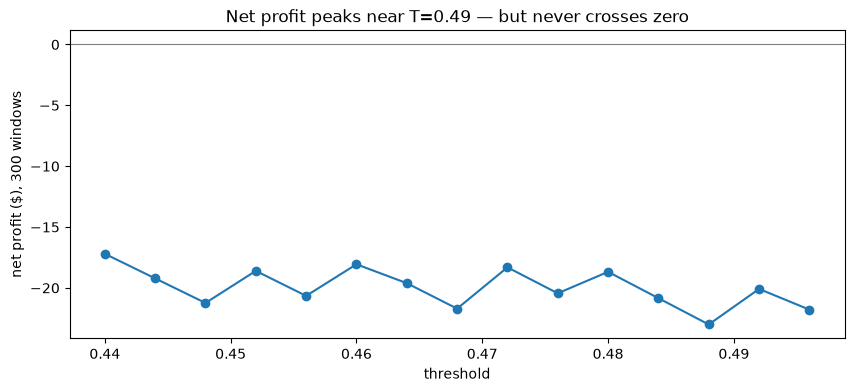

In [7]:
# Optimal threshold off the P&L curve (both fill models)
if TAPE_OK:
    Tg = np.round(np.arange(0.44, 0.498, 0.004), 3)
    for mode in ("trade_through", "sell_through"):
        sw = tape_threshold_sweep(tape_windows, Tg, base_cfg=TapeConfig(fill_mode=mode))
        b = sw.loc[sw.net_profit.idxmax()]
        print(f"{mode:13s}: optimal T={b.threshold:.3f}  net=${b.net_profit:7.2f}  "
              f"both-fill={b.both_fill_rate:5.1%}  unhedged-loss={b.unhedged_loss_rate:5.1%}")
    sw = tape_threshold_sweep(tape_windows, Tg, base_cfg=TapeConfig(fill_mode="trade_through"))
    plt.plot(sw.threshold, sw.net_profit, "o-"); plt.axhline(0, c="grey", lw=.8)
    plt.xlabel("threshold"); plt.ylabel(f"net profit ($), {len(tape_windows)} windows")
    plt.title("Net profit peaks near T=0.49 — but never crosses zero"); plt.show()

## 3 — Active-exit variant

The passive double-dip holds an unhedged leg to settlement ($0 if it loses). The
active-exit engine instead **abandons** an unhedged leg after `hold_timeout_s`:
sell the filled leg at the prevailing price and cancel the other bid. This caps the
single-leg loss — but you cross the spread on exit.

,hold_timeout_s,net_pnl,exit_win,exit_loss,locks
0,5,-8.17,31,200,69
1,10,-9.35,36,167,97
2,15,-9.69,22,160,118
3,20,-9.72,17,141,142
4,30,-9.65,5,127,168
5,45,-10.61,2,110,188
6,60,-10.53,2,101,197


passive (hold-to-settlement) net @ T=0.49: $-18.98


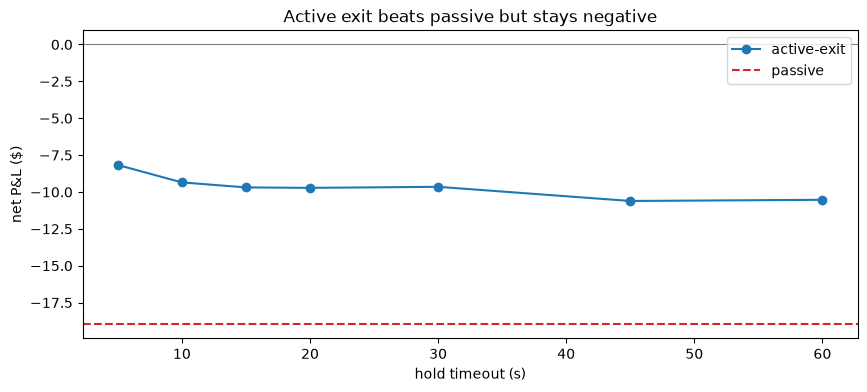

In [8]:
# Sweep the hold timeout; net P&L vs passive (T=0.49)
if TAPE_OK:
    pas = TapeBacktester(TapeConfig(threshold=0.49)).run(tape_windows)
    pas_net = sum(r.pnl for r in pas)
    rows = []
    for to in [5, 10, 15, 20, 30, 45, 60]:
        ar = ActiveExitBacktester(ActiveConfig(threshold=0.49, hold_timeout_s=to)).run(tape_windows)
        net = sum(r.pnl for r in ar)
        rows.append({"hold_timeout_s": to, "net_pnl": round(net, 2),
                     "exit_win": sum(r.outcome == EXIT_WIN for r in ar),
                     "exit_loss": sum(r.outcome == EXIT_LOSS for r in ar),
                     "locks": sum(r.outcome == ARB_LOCKED for r in ar)})
    df = pd.DataFrame(rows)
    display(df)
    print(f"passive (hold-to-settlement) net @ T=0.49: ${pas_net:.2f}")
    plt.plot(df.hold_timeout_s, df.net_pnl, "o-", label="active-exit")
    plt.axhline(pas_net, ls="--", c="tab:red", label="passive")
    plt.axhline(0, c="grey", lw=.8); plt.xlabel("hold timeout (s)"); plt.ylabel("net P&L ($)")
    plt.title("Active exit beats passive but stays negative"); plt.legend(); plt.show()

## Verdict

On the best available *historical* data (the executed trade tape, look-ahead-safe):

- The double-dip is **real and frequent** — both legs do dip below `T` at different
  times — but **every single-leg fill is the loser** (`UNHEDGED_WIN` ≈ 0). When the
  market oscillates both legs fill (a lock, +`1−2T` ≈ 2¢); when it **trends** only the
  cheap losing side fills and the winner never reverses (−~49¢).
- **Optimal threshold ≈ 0.49**, and net P&L there is still **negative** (≈ −$0.04/win):
  break-even needs the clean-trend rate < ~4%, but it is ~11%.
- **Active exit** improves on passive (caps the unhedged loss) but **stays negative**
  once you account for the exit spread.

**No tradeable arb edge on this evidence.** The one untested lever is whether
early-window **quote** reversals (the order-book mid, which moves without trading)
are *fillable* — historical book depth doesn't exist publicly, so the live CLOB
collector (`polymarket_arb.collector --forever`) gathers it going forward. See the
companion notebook `market_dynamics_and_reversal.ipynb` for why the markets are
efficiently priced (a near-martingale digital on a driftless diffusion).